In [65]:
import pandas as pd
import numpy as np

In [66]:
# 1. Carregar os 4 ficheiros CSV fornecidos
wind_df = pd.read_csv('wind_288_per_MW.csv')
solar_df = pd.read_csv('solar_288h_representative_matrix.csv')
hydro_df = pd.read_csv('hydro_288h.csv')
load_df = pd.read_csv('Universal_Load_288.csv')

# 2. Parâmetros específicos da ilha de La Palma (Grupo 15)
P_BASE = 4.0   # MW (Tabela 4)
P_PEAK = 11.5  # MW (Tabela 4)
DAYS_IN_MONTH = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# 3. Transformação matemática da procura (Equação 1 do enunciado)
# P_demand(m,h) = P_base + M_0-1(m,h) * (P_peak - P_base)
load_df['P_demand_MW'] = P_BASE + load_df['Dimensionless_Load'] * (P_PEAK - P_BASE)

wind_dist = wind_df['Wind_pu']
solar_dist = solar_df['P_AC_per_MWp']
hydro_dist = hydro_df['Power (W)']


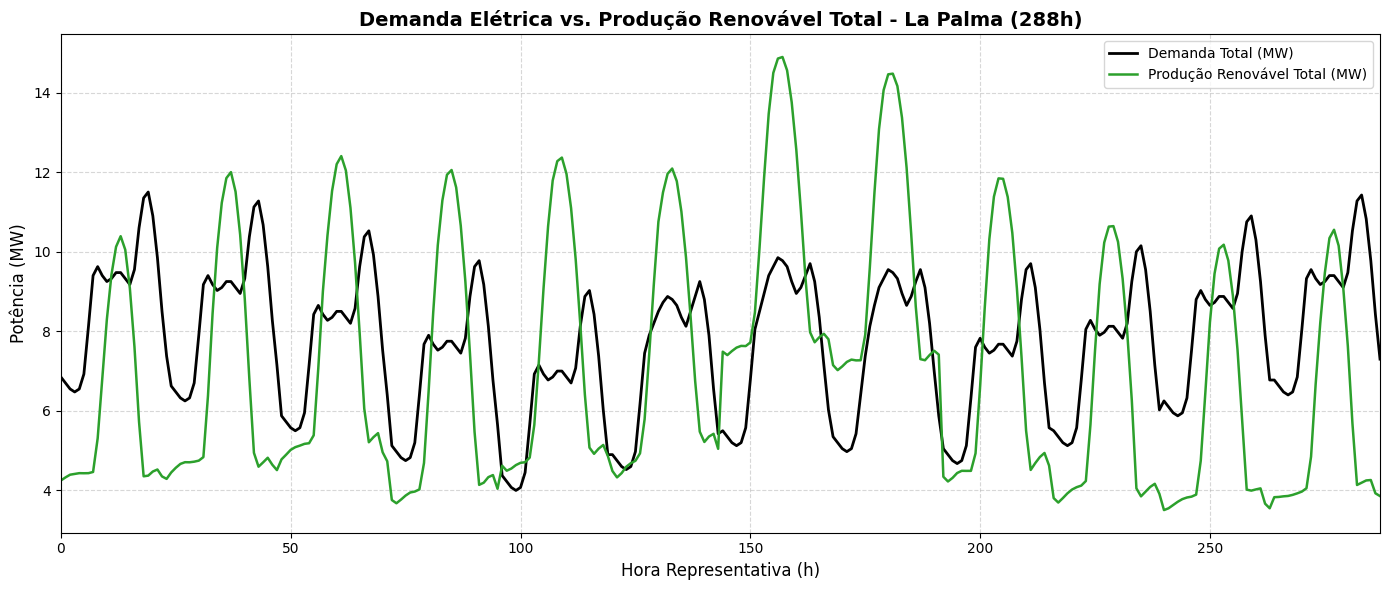

In [67]:
solar_power = 10
wind_power = 9.4
hydro_power = 0.84
renewables = solar_power * solar_dist + wind_power * wind_dist + hydro_dist / 1e6
demand = load_df['P_demand_MW']

plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda Total (MW)', color='black', linewidth=2)
plt.plot(renewables, label='Produção Renovável Total (MW)', color='tab:green', linewidth=1.8)

plt.title('Demanda Elétrica vs. Produção Renovável Total - La Palma (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()



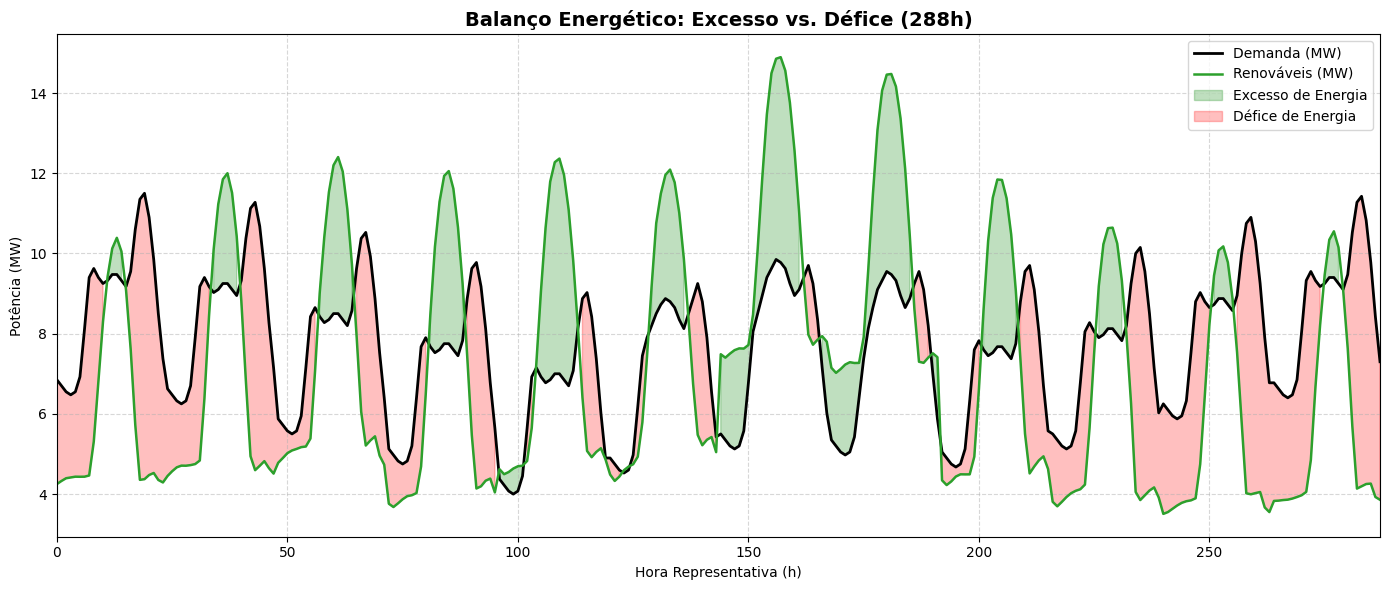

In [68]:
plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda (MW)', color='black', linewidth=2)
plt.plot(renewables, label='Renováveis (MW)', color='tab:green', linewidth=1.8)

# Preencher áreas de excesso (Renováveis > Demanda)
plt.fill_between(range(288), demand, renewables, where=(renewables >= demand), 
                 color='green', alpha=0.25, label='Excesso de Energia')

# Preencher áreas de défice (Renováveis < Demanda)
plt.fill_between(range(288), demand, renewables, where=(renewables < demand), 
                 color='red', alpha=0.25, label='Défice de Energia')

plt.title('Balanço Energético: Excesso vs. Défice (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)')
plt.ylabel('Potência (MW)')
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

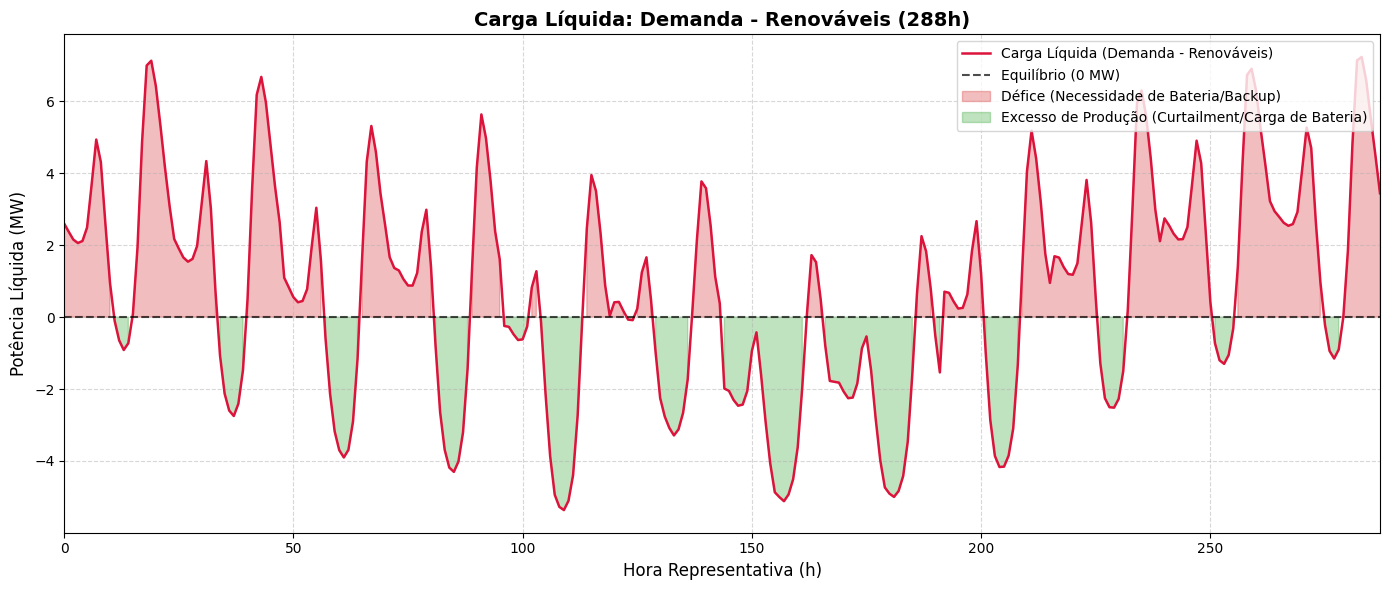

In [69]:
# Cálculo da Carga Líquida
net_load = demand - renewables

plt.figure(figsize=(14, 6))

# Linha da Carga Líquida
plt.plot(net_load, color='crimson', linewidth=1.8, label='Carga Líquida (Demanda - Renováveis)')

# Linha de referência (0 MW)
plt.axhline(0, color='black', linestyle='--', alpha=0.7, label='Equilíbrio (0 MW)')

# Preenchimento visual
plt.fill_between(range(288), net_load, 0, where=(net_load > 0), color='tab:red', alpha=0.3, label='Défice (Necessidade de Bateria/Backup)')
plt.fill_between(range(288), net_load, 0, where=(net_load < 0), color='tab:green', alpha=0.3, label='Excesso de Produção (Curtailment/Carga de Bateria)')

plt.title('Carga Líquida: Demanda - Renováveis (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência Líquida (MW)', fontsize=12)
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [70]:
# 1. Cálculo do perfil de potência térmica (MW) hora a hora
P_thermal = np.maximum(0, demand - renewables)

# 2. Principais parâmetros de dimensionamento
P_thermal_max = P_thermal.max()
print(f"Potência Térmica Máxima Necessária: {P_thermal_max:.2f} MW")

Potência Térmica Máxima Necessária: 7.23 MW


In [71]:
import pandas as pd
import numpy as np

DAYS_IN_MONTH = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# Criar um array com 288 elementos contendo os dias correspondentes a cada hora
days_per_hour = np.repeat(DAYS_IN_MONTH, 24)


# 1. Défice puro de potência (Demanda - Renováveis)
net_load = demand - renewables
P_thermal_raw = np.maximum(0, net_load)

# 2. Capacidade Nominal e Carga Mínima Técnica (30%)
P_CAP = P_thermal_raw.max()       # ~7.303 MW
P_MIN = 0.30 * P_CAP              # ~2.191 MW


# Cenário B: Must-run (nunca baixa de P_MIN)
P_thermal_B = np.maximum(P_MIN, P_thermal_raw)

# 4. Cálculo da Energia Gerada nas 288h (MWh)
E_thermal_B = P_thermal_B.sum()

# 1. Energia Anual (MWh)
E_demand_annual = (demand * days_per_hour).sum()
E_renewables_annual = (renewables * days_per_hour).sum()


# Cenário B (Must-run contínuo a 30%)
E_thermal_B_annual = (P_thermal_B * days_per_hour).sum()

print(f"Demanda Total Anual: {E_demand_annual:,.2f} MWh")
print(f"Produção Renovável Total Anual: {E_renewables_annual:,.2f} MWh")
print(f"Energia Térmica Anual (Cenário B): {E_thermal_B_annual:,.2f} MWh")

Demanda Total Anual: 67,976.55 MWh
Produção Renovável Total Anual: 62,204.12 MWh
Energia Térmica Anual (Cenário B): 24,241.49 MWh


In [72]:
#Energia Renovável Anual por Fonte (MWh)
E_solar_annual = (solar_power * solar_dist * days_per_hour).sum()
E_wind_annual = (wind_power * wind_dist * days_per_hour).sum()
E_hydro_annual = (hydro_dist/1e6 * days_per_hour).sum()
E_renewables_annual = (renewables * days_per_hour).sum()

# 3. Demanda Total Anual (MWh)
E_demand_annual = (demand * days_per_hour).sum()

# 4. Energia Térmica Anual (MWh)
E_thermal_B_annual = (P_thermal_B * days_per_hour).sum()

# Impressão dos Resultados
print(f"Demanda Total Anual: {E_demand_annual:,.2f} MWh")
print(f"--- PRODUÇÃO RENOVÁVEL ---")
print(f"Produção Solar Anual: {E_solar_annual:,.2f} MWh")
print(f"Produção Eólica Anual: {E_wind_annual:,.2f} MWh")
print(f"Produção Hídrica Anual: {E_hydro_annual:,.2f} MWh")
print(f"Produção Renovável Total Anual: {E_renewables_annual:,.2f} MWh")
print(f"--- PRODUÇÃO TÉRMICA ---")
print(f"Energia Térmica Anual (Cenário B): {E_thermal_B_annual:,.2f} MWh")

Demanda Total Anual: 67,976.55 MWh
--- PRODUÇÃO RENOVÁVEL ---
Produção Solar Anual: 20,305.98 MWh
Produção Eólica Anual: 37,320.59 MWh
Produção Hídrica Anual: 4,577.55 MWh
Produção Renovável Total Anual: 62,204.12 MWh
--- PRODUÇÃO TÉRMICA ---
Energia Térmica Anual (Cenário B): 24,241.49 MWh


In [73]:
# 1. Potências Instaladas (MW)
VRE_MW = solar_power + wind_power                  # 19.20 MW
P_hydro_max = hydro_dist.max()                     # 0.839 MW
Total_Installed_MW = VRE_MW + P_CAP + P_hydro_max   # 27.34 MW

# 2. Energias Anuais (MWh)
E_vre_annual = E_solar_annual + E_wind_annual       # 56,832.51 MWh

# 3. Métricas VRE
vre_energy_penetration = (E_vre_annual / E_demand_annual) * 100
vre_capacity_penetration = (VRE_MW / Total_Installed_MW) * 100
vre_overbuild_ratio = (VRE_MW / P_PEAK) * 100

print(f"VRE Energy Penetration (% AEP): {vre_energy_penetration:.1f}%")
print(f"VRE Capacity Penetration (% MW): {vre_capacity_penetration:.1f}%")
print(f"VRE Overbuild Ratio: {vre_overbuild_ratio:.1f}%")

VRE Energy Penetration (% AEP): 84.8%
VRE Capacity Penetration (% MW): 0.0%
VRE Overbuild Ratio: 168.7%


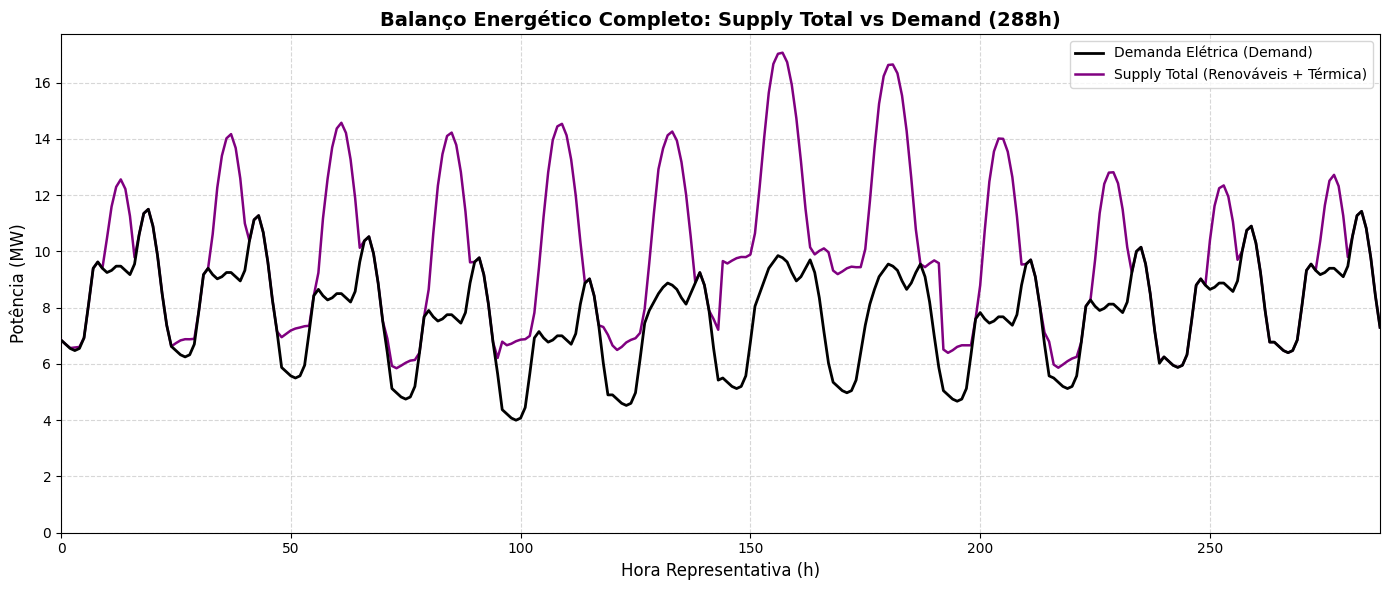

In [74]:

# 3. Supply Total (Renováveis + Não Renováveis)
total_supply = renewables + P_thermal_B

# 4. Gráfico
plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda Elétrica (Demand)', color='black', linewidth=2, zorder=4)
plt.plot(total_supply, label='Supply Total (Renováveis + Térmica)', color='purple', linewidth=1.8, zorder=3)

plt.title('Balanço Energético Completo: Supply Total vs Demand (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, 287)
plt.ylim(bottom=0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [76]:

# 5. CÁLCULO DAS MÉTRICAS DA TABELA
Total_VRE_MW = solar_power + wind_power + hydro_power    
Total_Installed_MW = Total_VRE_MW + P_CAP           

# 1. VRE Energy Penetration (% AEP)
vre_energy_pen_net = ((E_demand_annual - E_thermal_B_annual) / E_demand_annual) * 100

# 2. VRE Capacity Penetration (% MW)
vre_capacity_pen = (Total_VRE_MW / Total_Installed_MW) * 100

# 3. VRE Overbuild Ratio (%)
vre_overbuild_ratio = (Total_VRE_MW / P_PEAK) * 100

# 6. Apresentação dos Resultados

print("     RESULTADOS DAS MÉTRICAS VRE")

print(f"VRE Energy Penetration (% AEP):           {vre_energy_pen_net:.1f}%")
print(f"VRE Capacity Penetration (% MW):          {vre_capacity_pen:.1f}%")
print(f"VRE Overbuild Ratio:                      {vre_overbuild_ratio:.0f}%")


     RESULTADOS DAS MÉTRICAS VRE
VRE Energy Penetration (% AEP):           64.3%
VRE Capacity Penetration (% MW):          73.7%
VRE Overbuild Ratio:                      176%
